# Workshop 2 - Exploring the Silver layer (Team 2, Flood Monitoring and Risk, Texas)

This notebook reads the Parquet files written by the `silver_flood_processing_dag` with **Pandas**, checks their
schema, and follows each file back to the Bronze JSON it came from.

Silver naming convention: `datalake_silver/<topic>_YYYYMMDD_HHMMSS_from_<bronze file>.parquet` (UTC time of the processing run, then the Bronze file it came from).

In [1]:
import json
from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SILVER, BRONZE = ROOT / "datalake_silver", ROOT / "datalake_bronze"
files = sorted(SILVER.glob("*.parquet"))
pd.DataFrame([{"file": f.name, "topic": f.stem.split("_20")[0], "rows": pq.ParquetFile(f).metadata.num_rows,
               "size_kb": round(f.stat().st_size / 1024, 1)} for f in files])

,file,topic,rows,size_kb
0,daily_precipitation_20261116_234551_from_texas...,daily_precipitation,124,16.0
1,daily_precipitation_20261117_000251_from_texas...,daily_precipitation,30662,2319.6
2,flood_events_20261116_234551_from_texas_flood_...,flood_events,8000,3182.1
3,nws_alerts_20261116_234551_from_texas_flood_so...,nws_alerts,60,32.8
4,nws_observations_20261116_234551_from_texas_fl...,nws_observations,82,15.3
5,nws_observations_20261117_000251_from_texas_fl...,nws_observations,6,8.5


## 1. Read one Silver file and inspect its schema

In [2]:
f = sorted(SILVER.glob("flood_events_*.parquet"))[-1]
events_one = pd.read_parquet(f)
print(f.name, events_one.shape)
print(pq.read_schema(f).to_string(show_schema_metadata=False))

flood_events_20261116_234551_from_texas_flood_sources_20261116_233000.parquet (8000, 31)
storm_event_id: string not null
episode_id: string
event_type: string not null
begin_utc: timestamp[us, tz=UTC] not null
end_utc: timestamp[us, tz=UTC]
cz_type: string not null
cz_fips: string not null
county: string not null
latitude: double
longitude: double
location_known: bool not null
flood_cause: string not null
damage_property_usd: double
damage_crops_usd: double
damage_missing: bool not null
is_outlier_damage: bool not null
deaths_direct: int32 not null
deaths_indirect: int32 not null
injuries_direct: int32 not null
injuries_indirect: int32 not null
narrative_clean: string
narrative_tokens: list<element: string>
  child 0, element: string
impact_terms: list<element: string>
  child 0, element: string
severity_level: int8 not null
storm_events_file: string
event_id: string not null
source_system: string not null
record_hash: string not null
is_update: bool not null
bronze_source_file: string

In [3]:
events_one[["storm_event_id", "event_type", "begin_utc", "county", "latitude", "longitude",
            "damage_property_usd", "damage_missing", "severity_level", "impact_terms", "bronze_source_file"]].head()

,storm_event_id,event_type,begin_utc,county,latitude,longitude,damage_property_usd,damage_missing,severity_level,impact_terms,bronze_source_file
0,248852,Flash Flood,2010-07-09 03:00:00+00:00,Upton,31.1300,-102.2300,20000.0,False,2,[],texas_flood_sources_20261116_233000.json
1,214185,Flood,2010-01-15 20:30:00+00:00,Calhoun,28.5055,-96.6506,0.0,False,2,[creek],texas_flood_sources_20261116_233000.json
2,254554,Flood,2010-07-08 21:00:00+00:00,San Patricio,28.1412,-97.8154,0.0,False,2,[],texas_flood_sources_20261116_233000.json
3,205181,Flash Flood,2010-02-04 06:00:00+00:00,Bexar,29.7378,-98.4942,0.0,False,3,"[low water crossing, vehicle, creek]",texas_flood_sources_20261116_233000.json
4,253490,Flood,2010-07-08 06:00:00+00:00,Webb,27.7068,-99.7792,5250000.0,False,3,"[evacuat, creek, river]",texas_flood_sources_20261116_233000.json


## 2. Traceability: Parquet metadata and the Silver manifest

In [4]:
meta = pq.read_metadata(f).metadata
print("bronze_source_file:", meta[b"bronze_source_file"].decode())
print("pipeline_version  :", meta[b"pipeline_version"].decode())
print("dedup stats       :", json.loads(meta[b"preprocessing_stats"]))

bronze_source_file: texas_flood_sources_20261116_233000.json
pipeline_version  : 0.2.0
dedup stats       : {'rows_in': 8000, 'already_in_silver': 0, 'updates': 0, 'rows_new': 8000}


In [5]:
manifest = pd.read_json(SILVER / "_manifest.jsonl", lines=True)
pd.DataFrame([{"bronze_file": r.bronze_file, "topic": t, **o} for r in manifest.itertuples()
              for t, o in r.outputs.items()])

,bronze_file,topic,rows_in,already_in_silver,updates,rows_new,rows_written,file
0,texas_flood_sources_20261116_233000.json,nws_observations,82,0.0,0.0,82.0,82.0,nws_observations_20261116_234551_from_texas_fl...
1,texas_flood_sources_20261116_233000.json,nws_alerts,60,0.0,0.0,60.0,60.0,nws_alerts_20261116_234551_from_texas_flood_so...
2,texas_flood_sources_20261116_233000.json,daily_precipitation,124,0.0,0.0,124.0,124.0,daily_precipitation_20261116_234551_from_texas...
3,texas_flood_sources_20261116_233000.json,flood_events,8000,0.0,0.0,8000.0,8000.0,flood_events_20261116_234551_from_texas_flood_...
4,texas_flood_sources_20261116_234500.json,nws_observations,0,NaN,NaN,NaN,NaN,NaN
5,texas_flood_sources_20261116_234500.json,nws_alerts,60,60.0,0.0,0.0,NaN,NaN
6,texas_flood_sources_20261116_234500.json,daily_precipitation,0,NaN,NaN,NaN,NaN,NaN
7,texas_flood_sources_20261116_234500.json,flood_events,0,NaN,NaN,NaN,NaN,NaN
8,texas_flood_sources_20261117_000000.json,nws_observations,84,78.0,0.0,6.0,6.0,nws_observations_20261117_000251_from_texas_fl...
9,texas_flood_sources_20261117_000000.json,nws_alerts,60,60.0,0.0,0.0,NaN,NaN


## 3. Load every file of a topic at once (as the Gold layer will)

In [6]:
def load_topic(topic):
    return pd.concat([pd.read_parquet(p) for p in sorted(SILVER.glob(f"{topic}_*.parquet"))], ignore_index=True)

events = load_topic("flood_events")
precip = load_topic("daily_precipitation")
obs = load_topic("nws_observations")
alerts = load_topic("nws_alerts")
for name, df in [("flood_events", events), ("daily_precipitation", precip),
                 ("nws_observations", obs), ("nws_alerts", alerts)]:
    print(f"{name:20s} rows={len(df):6d}  duplicated event_id={df.event_id.duplicated().sum()}  "
          f"bronze files={df.bronze_source_file.nunique()}")

flood_events         rows=  8000  duplicated event_id=0  bronze files=1
daily_precipitation  rows= 30786  duplicated event_id=0  bronze files=2
nws_observations     rows=    88  duplicated event_id=0  bronze files=2
nws_alerts           rows=    60  duplicated event_id=0  bronze files=1


## 4. Data types and remaining nulls after preprocessing

In [7]:
summary = pd.DataFrame({"dtype": events.dtypes.astype(str), "null_%": events.isna().mean().mul(100).round(1)})
summary

,dtype,null_%
storm_event_id,str,0.0
episode_id,str,0.0
event_type,str,0.0
begin_utc,"datetime64[us, UTC]",0.0
end_utc,"datetime64[us, UTC]",0.0
cz_type,str,0.0
cz_fips,str,0.0
county,str,0.0
latitude,float64,0.0
longitude,float64,0.0


## 5. Quick look at the content

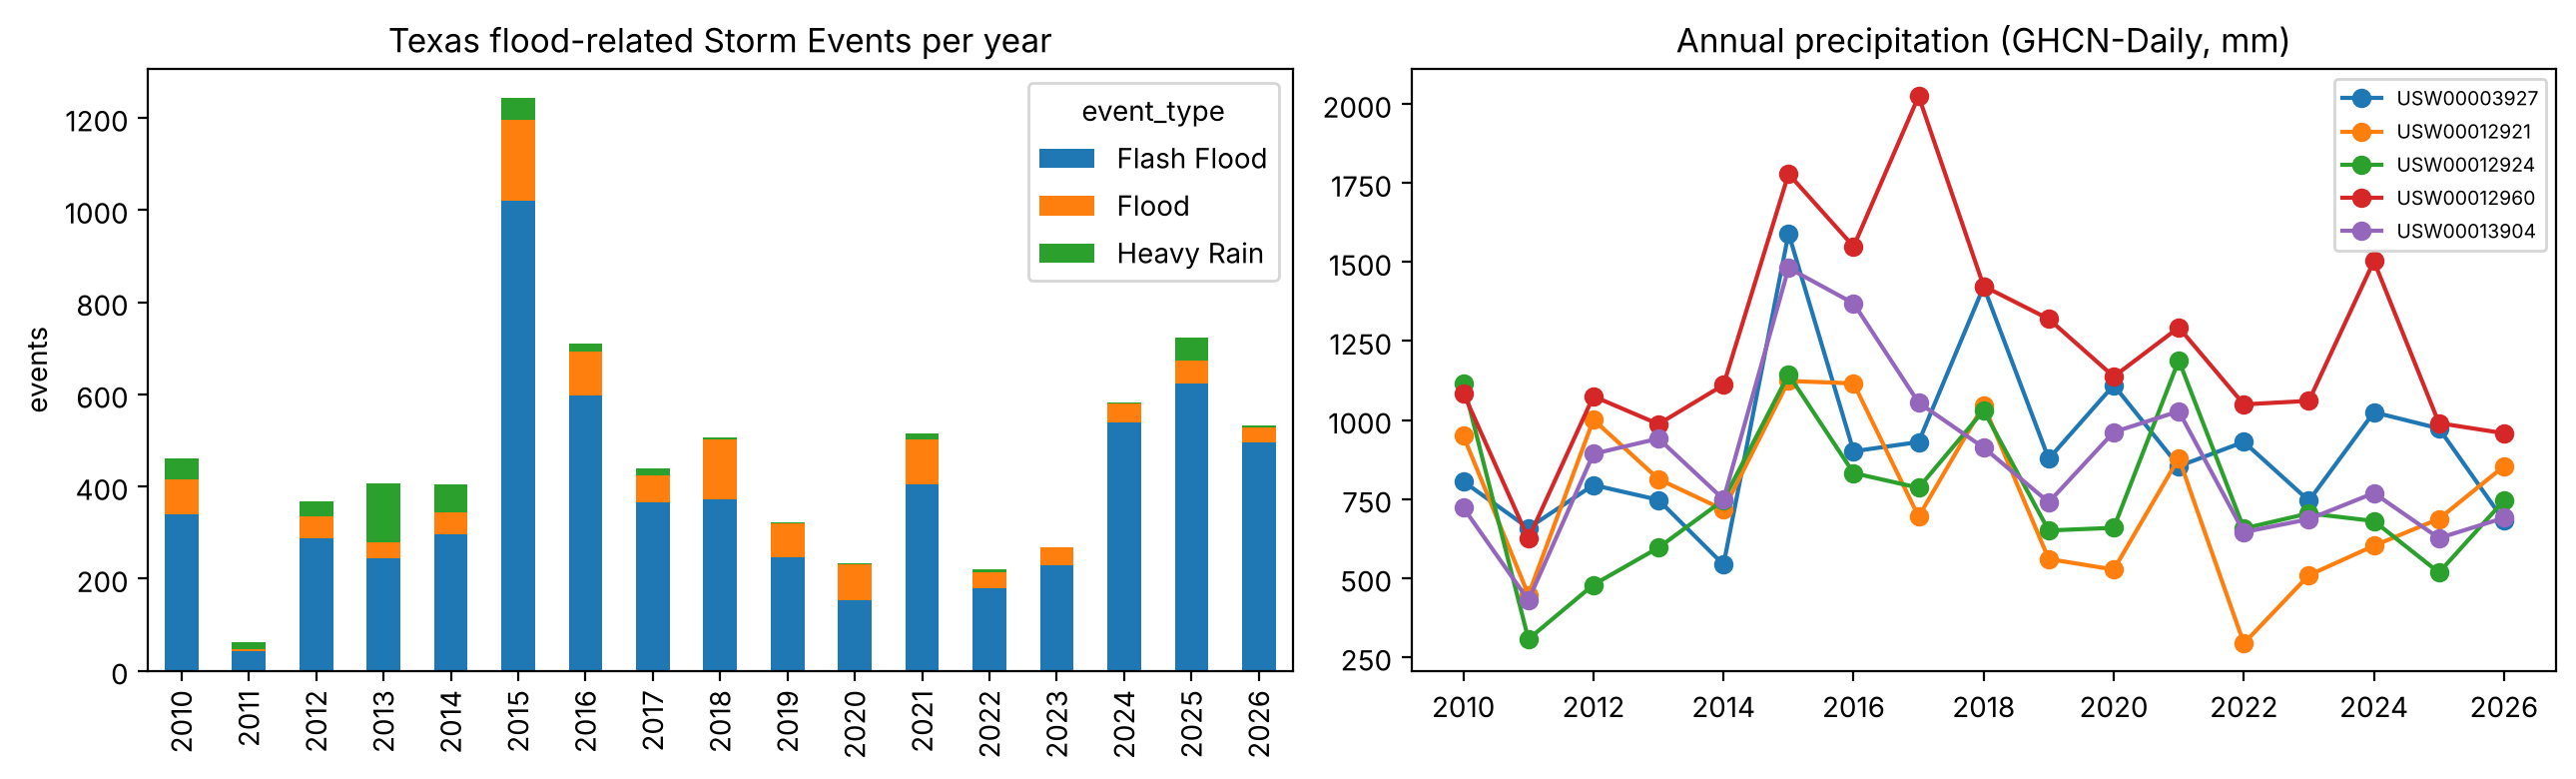

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
(events.assign(year=events.begin_utc.dt.year).groupby(["year", "event_type"]).size()
       .unstack(fill_value=0).plot.bar(stacked=True, ax=axes[0]))
axes[0].set_title("Texas flood-related Storm Events per year"); axes[0].set_xlabel(""); axes[0].set_ylabel("events")
annual = (precip.assign(year=pd.to_datetime(precip.obs_date).dt.year)
                .groupby(["year", "ghcn_station_id"]).prcp_mm.sum().unstack())
annual.plot(ax=axes[1], marker="o")
axes[1].set_title("Annual precipitation (GHCN-Daily, mm)"); axes[1].set_xlabel(""); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [9]:
print("Wettest station-days (flagged as outliers, kept on purpose):")
precip.sort_values("prcp_mm", ascending=False)[["ghcn_station_id", "station_id", "obs_date", "prcp_mm",
                                                 "is_outlier_iqr", "is_outlier_z", "severity_level"]].head(8)

Wettest station-days (flagged as outliers, kept on purpose):


,ghcn_station_id,station_id,obs_date,prcp_mm,is_outlier_iqr,is_outlier_z,severity_level
2919,USW00012960,KIAH,2017-08-27,408.2,True,True,3
8385,USW00013904,KAUS,2015-10-30,317.2,True,True,3
2423,USW00012960,KIAH,2016-04-18,252.0,True,True,3
13630,USW00012921,KSAT,2013-05-25,250.7,True,True,3
3672,USW00012960,KIAH,2019-09-19,233.9,True,False,3
8594,USW00013904,KAUS,2016-05-26,223.3,True,True,3
2918,USW00012960,KIAH,2017-08-26,212.6,True,False,3
9051,USW00013904,KAUS,2017-08-26,189.7,True,False,3


In [10]:
print("Most frequent impact terms found in the cleaned narratives:")
events.explode("impact_terms").impact_terms.value_counts().head(10)

Most frequent impact terms found in the cleaned narratives:


impact_terms
creek                 1411
river                 1088
water rescue           994
vehicle                904
stranded               538
low water crossing     509
bayou                  215
evacuat                201
swift water            168
roads closed           104
Name: count, dtype: int64

In [11]:
alerts[["nws_event", "message_type", "sent_utc", "onset_utc", "ends_utc", "area_desc", "severity_level", "impact_terms"]]

,nws_event,message_type,sent_utc,onset_utc,ends_utc,area_desc,severity_level,impact_terms
0,Flood Warning,Update,2026-11-16 15:44:00+00:00,2026-11-16 15:44:00+00:00,2026-11-18 05:48:00+00:00,mcmullen tx,3,[river]
1,Flood Advisory,Cancel,2026-11-16 03:45:00+00:00,2026-11-16 03:45:00+00:00,2026-11-16 05:00:00+00:00,cameron tx,1,[]
2,Flood Advisory,Update,2026-11-16 03:31:00+00:00,2026-11-16 03:31:00+00:00,2026-11-16 05:00:00+00:00,cameron tx,1,[]
3,Flood Advisory,Alert,2026-11-16 02:57:00+00:00,2026-11-16 02:57:00+00:00,2026-11-16 05:00:00+00:00,cameron tx,1,[]
4,Flood Warning,Update,2026-11-16 01:36:00+00:00,2026-11-16 01:36:00+00:00,2026-11-18 03:24:00+00:00,mcmullen tx,3,[river]
5,Flood Advisory,Alert,2026-11-15 21:14:00+00:00,2026-11-15 21:14:00+00:00,2026-11-16 00:15:00+00:00,brazoria tx,1,[creek]
6,Flood Warning,Update,2026-11-15 19:30:00+00:00,2026-11-15 19:30:00+00:00,2026-11-18 07:45:00+00:00,mcmullen tx,3,[river]
7,Flood Warning,Update,2026-11-15 15:47:00+00:00,2026-11-15 15:47:00+00:00,2026-11-18 10:00:00+00:00,mcmullen tx,3,[river]
8,Flood Advisory,Alert,2026-11-15 11:38:00+00:00,2026-11-15 11:38:00+00:00,2026-11-15 13:45:00+00:00,brazoria tx; matagorda tx,1,[creek]
9,Flood Advisory,Alert,2026-11-15 10:10:00+00:00,2026-11-15 10:10:00+00:00,2026-11-15 13:15:00+00:00,concho tx,1,[]


In [12]:
obs.groupby("station_id").agg(observations=("ts_utc", "size"), first=("ts_utc", "min"), last=("ts_utc", "max"),
                               metar_reports=("is_metar", "sum"),
                               precip_missing_pct=("precip_missing", lambda s: round(s.mean() * 100, 1)))

,observations,first,last,metar_reports,precip_missing_pct
station_id,,,,,
KAUS,16,2026-11-16 19:53:00+00:00,2026-11-16 23:40:00+00:00,4,100.0
KCRP,15,2026-11-16 19:51:00+00:00,2026-11-16 23:40:00+00:00,4,100.0
KDFW,14,2026-11-16 19:53:00+00:00,2026-11-16 23:40:00+00:00,3,100.0
KIAH,22,2026-11-16 19:25:00+00:00,2026-11-16 23:40:00+00:00,3,100.0
KSAT,21,2026-11-16 19:28:00+00:00,2026-11-16 23:40:00+00:00,4,100.0
